In [37]:
!pip install xgboost pandas scikit-learn

In [38]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the converted CSV file
df = pd.read_csv('football_train_data.csv')

print("Data loaded successfully!")
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Define your target variable 
target_col = 'FTR' 

# Drop non-numeric metadata and the target from your feature matrix
X = df.drop(columns=[target_col, 'HomeTeam', 'AwayTeam', 'Date'], errors='ignore')
y = df[target_col]

# Convert text-based targets (like 'H', 'D', 'A') into numeric codes for XGBoost
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialise and train the XGBoost classifier
model = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model.fit(X_train, y_train)

# 5. Evaluate the model performance
preds = model.predict(X_val)
print("Baseline Validation Accuracy:", accuracy_score(y_val, preds))

Data loaded successfully!
Dataset Shape (Rows, Columns): (37824, 90)
Baseline Validation Accuracy: 0.561929940515532


In [39]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load dataset
df = pd.read_csv('football_train_data.csv')
target_col = 'FTR'

# 2. Automatically identify and drop columns from competing bookmakers (GB, IW, LB, SO, SB, WH)
# while keeping match stats and Bet365 odds intact
other_bookie_prefixes = ('GB', 'IW', 'LB', 'SO', 'SB', 'WH')
cols_to_drop = [col for col in df.columns if col.startswith(other_bookie_prefixes)]

# Also drop metadata/target
metadata_cols = [target_col, 'HomeTeam', 'AwayTeam', 'Date']
drop_list = list(set(cols_to_drop + metadata_cols))

# 3. Create feature matrix X and target y
X = df.drop(columns=[col for col in drop_list if col in df.columns], errors='ignore')
y = df[target_col]

if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 4. Split data (80/20 train/validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train model with only Bet365 odds and match stats
model_b365 = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model_b365.fit(X_train, y_train)

# 6. Evaluate
preds_b365 = model_b365.predict(X_val)
print("Remaining Feature Count:", X.shape[1])
print("Validation Accuracy (Bet365 Only):", accuracy_score(y_val, preds_b365))

Remaining Feature Count: 63
Validation Accuracy (Bet365 Only): 0.5612690019828156


In [7]:
# Pure Betting Odds Only
odds_cols = [c for c in X.columns if 'B365' in c or '365' in c]
X_odds = X[odds_cols]

X_tr_o, X_va_o, y_tr_o, y_va_o = train_test_split(X_odds, y, test_size=0.2, random_state=42)
model_odds = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_odds.fit(X_tr_o, y_tr_o)
print("Odds-Only Accuracy:", accuracy_score(y_va_o, model_odds.predict(X_va_o)))

# Pure Match Stats Only
stats_cols = [c for c in X.columns if c not in odds_cols]
X_stats = X[stats_cols]

X_tr_s, X_va_s, y_tr_s, y_va_s = train_test_split(X_stats, y, test_size=0.2, random_state=42)
model_stats = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_stats.fit(X_tr_s, y_tr_s)
print("Stats-Only Accuracy:", accuracy_score(y_va_s, model_stats.predict(X_va_s)))

Odds-Only Accuracy: 0.46226040978189026
Stats-Only Accuracy: 0.5614011896893589


In [40]:
import pandas as pd

# Get feature importance ranking
importances = pd.Series(model_b365.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Top 10 Most Important Features ---")
print(importances.head(10))

print("\n--- Bottom 10 Least Important Features ---")
print(importances.tail(10))

# Drop features with 0 or near-zero importance
top_features = importances[importances > 0.005].index
X_top = X[top_features]

X_tr_t, X_va_t, y_tr_t, y_va_t = train_test_split(X_top, y, test_size=0.2, random_state=42)
model_top = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_top.fit(X_tr_t, y_tr_t)
print("\nPruned Features Accuracy:", accuracy_score(y_va_t, model_top.predict(X_va_t)))

--- Top 10 Most Important Features ---
AST      0.092147
HST      0.091445
B365A    0.039507
AR       0.035294
B365H    0.034552
HC       0.030416
AC       0.027316
HR       0.027245
BWA      0.020166
SJA      0.018349
dtype: float32

--- Bottom 10 Least Important Features ---
X1XBD      0.008977
BFEH       0.008772
BVH        0.008695
BFDD       0.008671
BVD        0.008657
BFEAHA     0.008648
X1XBA      0.008407
BFE.2.5    0.008279
BMGMA      0.008238
CLD        0.007494
dtype: float32

Pruned Features Accuracy: 0.5611368142762723


In [41]:
from sklearn.metrics import classification_report, confusion_matrix

preds = model_b365.predict(X_val)
print("--- Classification Report ---")
print(classification_report(y_val, preds))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_val, preds))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.54      0.61      0.57      2231
           1       0.43      0.11      0.18      2061
           2       0.59      0.81      0.68      3273

    accuracy                           0.56      7565
   macro avg       0.52      0.51      0.48      7565
weighted avg       0.53      0.56      0.51      7565

--- Confusion Matrix ---
[[1360  160  711]
 [ 700  229 1132]
 [ 470  146 2657]]


In [42]:
X_eng = X.copy()

# Add relative performance features
if 'HS' in X.columns and 'AS' in X.columns:
    X_eng['Shot_Diff'] = X_eng['HS'] - X_eng['AS']
if 'HST' in X.columns and 'AST' in X.columns:
    X_eng['Target_Shot_Diff'] = X_eng['HST'] - X_eng['AST']
if 'HC' in X.columns and 'AC' in X.columns:
    X_eng['Corner_Diff'] = X_eng['HC'] - X_eng['AC']

# Train on engineered dataset
X_tr_e, X_va_e, y_tr_e, y_va_e = train_test_split(X_eng, y, test_size=0.2, random_state=42)
model_eng = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_eng.fit(X_tr_e, y_tr_e)
print("Engineered Features Accuracy:", accuracy_score(y_va_e, model_eng.predict(X_va_e)))

Engineered Features Accuracy: 0.5604758757435558


In [43]:
from sklearn.model_selection import cross_val_score, KFold
import xgboost as xgb

# 1. Initialise your model with all CPU cores enabled
model_cv = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42,
    n_jobs=-1
)

# 2. Set up 5-Fold Cross Validation with shuffling
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Compute accuracy across all 5 folds automatically
cv_scores = cross_val_score(model_cv, X, y, cv=kf, scoring='accuracy', n_jobs=-1)

print("Accuracy scores for each fold:", [f"{score:.4f}" for score in cv_scores])
print(f"Mean Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Accuracy scores for each fold: ['0.5613', '0.5581', '0.5603', '0.5462', '0.5543']
Mean Cross-Validation Accuracy: 0.5560 (+/- 0.0109)


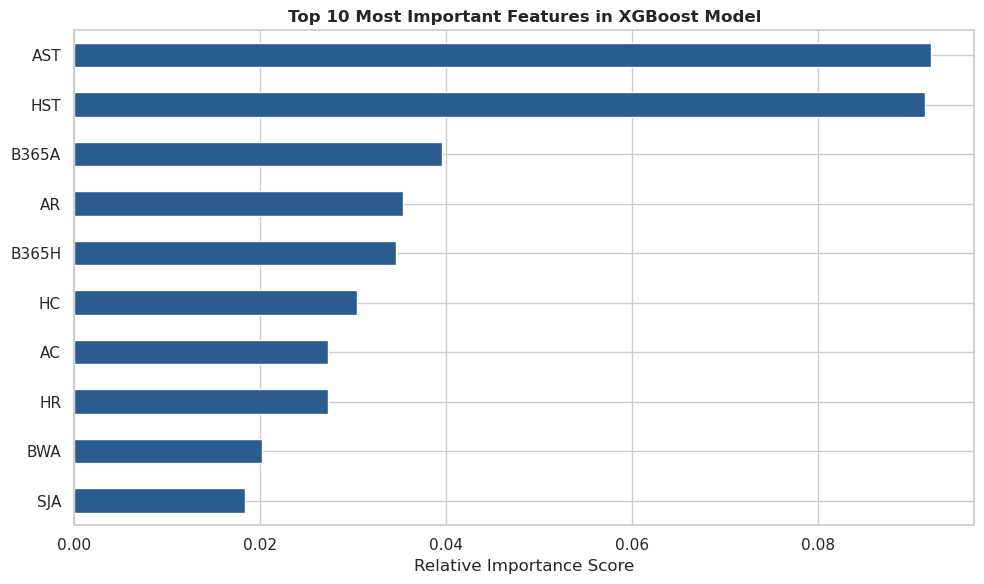

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances from your trained model
importances = pd.Series(model_b365.feature_importances_, index=X.columns)

# Plot top 10 features horizontally
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Important Features in XGBoost Model', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.gca().invert_yaxis()  # Put the highest at the top
plt.tight_layout()
plt.show()

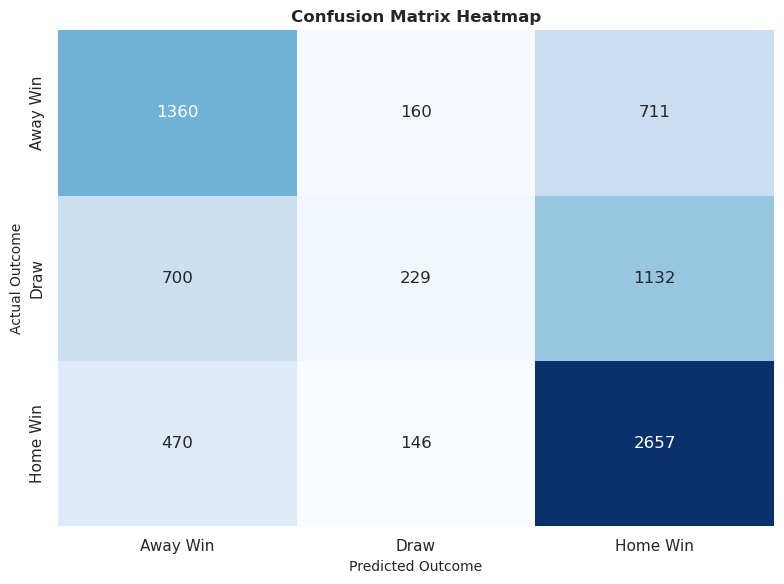

In [45]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_val, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Away Win', 'Draw', 'Home Win'],
            yticklabels=['Away Win', 'Draw', 'Home Win'])
plt.title('Confusion Matrix Heatmap', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=10)
plt.ylabel('Actual Outcome', fontsize=10)
plt.tight_layout()
plt.show()

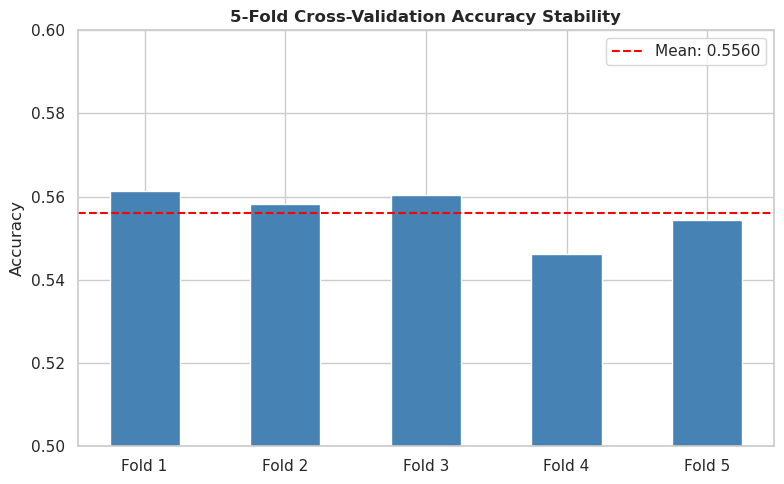

In [46]:
plt.figure(figsize=(8, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_scores))]
plt.bar(folds, cv_scores, color='#4682B4', width=0.5)
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label=f'Mean: {cv_scores.mean():.4f}')
plt.ylim(0.5, 0.6)  # Focus the axis around your accuracy range
plt.title('5-Fold Cross-Validation Accuracy Stability', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the converted CSV file
df = pd.read_csv('football_test_data.csv')

print("Data loaded successfully!")
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Define your target variable 
target_col = 'FTR' 

# Drop non-numeric metadata and the target from your feature matrix
X = df.drop(columns=[target_col, 'HomeTeam', 'AwayTeam', 'Date'], errors='ignore')
y = df[target_col]

# Convert text-based targets (like 'H', 'D', 'A') into numeric codes for XGBoost
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialise and train the XGBoost classifier
model = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model.fit(X_train, y_train)

# 5. Evaluate the model performance
preds = model.predict(X_val)
print("Test Accuracy:", accuracy_score(y_val, preds))

Data loaded successfully!
Dataset Shape (Rows, Columns): (8740, 90)
Test Accuracy: 0.5966819221967964


In [32]:
# 1. Align your test data columns to match the exact features your model was trained on
X_test_final = test_df[model.feature_names_in_]
y_test = test_df['FTR']

# Convert text-based targets to numeric if your training set used numeric codes
if y_test.dtype == 'object':
    y_test = y_test.astype('category').cat.codes

# 2. Generate predictions using your pre-trained model
y_pred = model.predict(X_test_final)

# 3. Calculate your final test accuracy
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Final Test Accuracy (includes target leakage so we don't use this): {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Final Test Accuracy (includes target leakage so we don't use this): 0.7064

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.75      0.73      2605
           1       0.71      0.31      0.43      2159
           2       0.71      0.89      0.79      3976

    accuracy                           0.71      8740
   macro avg       0.71      0.65      0.65      8740
weighted avg       0.71      0.71      0.68      8740



In [26]:
# Align test data to the exact pre-match features expected by your odds model
X_test_clean = test_df[model_odds.feature_names_in_]
y_test = test_df['FTR']

# Convert text-based targets to numeric codes if necessary
if y_test.dtype == 'object':
    y_test = y_test.astype('category').cat.codes

# Generate predictions using the clean pre-match model
y_pred = model_odds.predict(X_test_clean)

# Calculate honest final test accuracy
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Clean Final Test Accuracy: {test_accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Clean Final Test Accuracy: 0.5335

Classification Report:
              precision    recall  f1-score   support

           0       0.49      0.55      0.52      2605
           1       0.28      0.02      0.03      2159
           2       0.56      0.81      0.66      3976

    accuracy                           0.53      8740
   macro avg       0.44      0.46      0.40      8740
weighted avg       0.47      0.53      0.46      8740


Confusion Matrix:
[[1423   53 1129]
 [ 723   37 1399]
 [ 729   44 3203]]


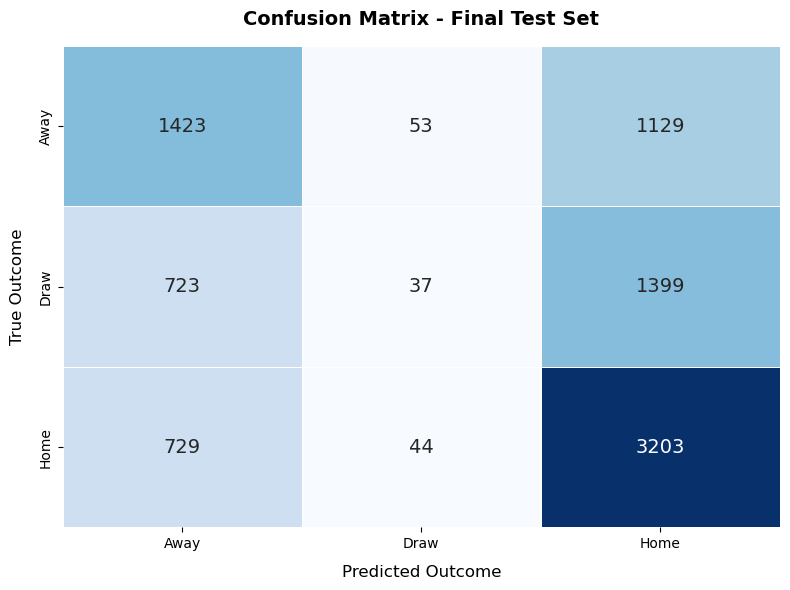

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Set up the plot aesthetics
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    cbar=False,
    xticklabels=['Away', 'Draw', 'Home'], 
    yticklabels=['Away', 'Draw', 'Home'],
    linewidths=0.5,
    annot_kws={'size': 14}
)

# Add titles and labels
plt.title('Confusion Matrix - Final Test Set', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=12, labelpad=10)
plt.ylabel('True Outcome', fontsize=12, labelpad=10)

plt.tight_layout()
plt.show()

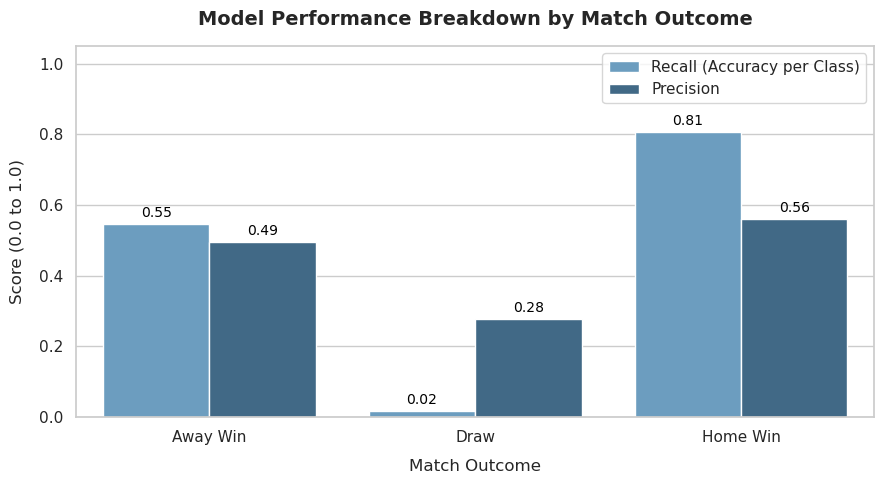

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Compute metrics for each class
precision, recall, f1, support = precision_recall_fscore_support(y_test, y_pred)

# Prepare data for plotting
metrics_df = pd.DataFrame({
    'Outcome': ['Away Win', 'Draw', 'Home Win'] * 2,
    'Score': list(recall) + list(precision),
    'Metric Type': ['Recall (Accuracy per Class)'] * 3 + ['Precision'] * 3
})

# Set up the plot aesthetics
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    x='Outcome', 
    y='Score', 
    hue='Metric Type', 
    data=metrics_df, 
    palette='Blues_d'
)

# Add titles, labels, and limits
plt.title('Model Performance Breakdown by Match Outcome', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Match Outcome', fontsize=12, labelpad=10)
plt.ylabel('Score (0.0 to 1.0)', fontsize=12, labelpad=10)
plt.ylim(0, 1.05)

# Add numeric data labels on top of each bar for clarity
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.2f}',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', 
            va='bottom',
            fontsize=10, 
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(title='', loc='upper right')
plt.tight_layout()
plt.show()

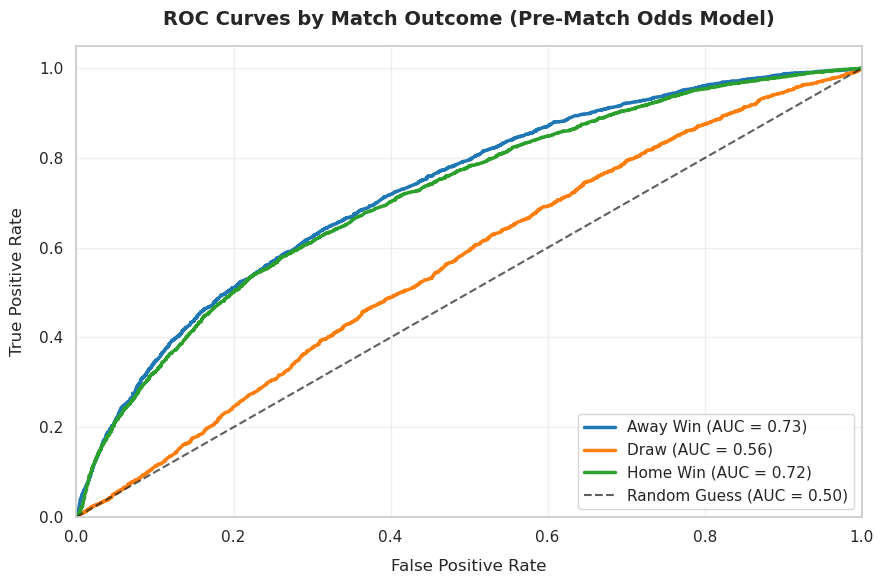

In [31]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# 1. Binarize the test labels for multi-class ROC calculation (0: Away, 1: Draw, 2: Home)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# 2. Get predicted probabilities from your pre-match odds model
y_score = model_odds.predict_proba(X_test_clean)

# 3. Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

class_names = ['Away Win', 'Draw', 'Home Win']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

plt.figure(figsize=(9, 6))

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
    plt.plot(
        fpr[i], 
        tpr[i], 
        color=colors[i], 
        lw=2.5, 
        label=f'{class_names[i]} (AUC = {roc_auc[i]:.2f})'
    )

# Plot diagonal reference line for random guessing (AUC = 0.50)
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label='Random Guess (AUC = 0.50)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12, labelpad=10)
plt.ylabel('True Positive Rate', fontsize=12, labelpad=10)
plt.title('ROC Curves by Match Outcome (Pre-Match Odds Model)', fontsize=14, pad=15, fontweight='bold')
plt.legend(loc="lower right", fontsize=11, frameon=True)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
import pandas as pd
from sklearn.metrics import accuracy_score, log_loss, precision_recall_fscore_support

# 1. Compute metrics
xgb_pred = model_odds.predict(X_test_clean)
xgb_proba = model_odds.predict_proba(X_test_clean)

accuracy = accuracy_score(y_test, xgb_pred)
logloss = log_loss(y_test, xgb_proba)
precision, recall, f1, support = precision_recall_fscore_support(y_test, xgb_pred)

# 2. Build a summary DataFrame for per-class performance
class_summary_df = pd.DataFrame({
    'Outcome': ['Away Win', 'Draw', 'Home Win'],
    'Precision': [f'{p:.2f}' for p in precision],
    'Recall (Accuracy)': [f'{r:.2f}' for r in recall],
    'F1-Score': [f'{val:.2f}' for val in f1],
    'Support (Matches)': support
})

print(f"=== XGBOOST OVERALL METRICS ===")
print(f"Overall Accuracy : {accuracy * 100:.2f}%")
print(f"Multi-Class Log-Loss: {logloss:.4f}\n")

print("=== PER-CLASS BREAKDOWN ===")
print(class_summary_df.to_string(index=False))

=== XGBOOST OVERALL METRICS ===
Overall Accuracy : 53.35%
Multi-Class Log-Loss: 0.9799

=== PER-CLASS BREAKDOWN ===
 Outcome Precision Recall (Accuracy) F1-Score  Support (Matches)
Away Win      0.49              0.55     0.52               2605
    Draw      0.28              0.02     0.03               2159
Home Win      0.56              0.81     0.66               3976
